# Processed half-time dataset

We inspect missing metadata, source overlap, experimental conditions and half-life distributions in the two processed TSV tables. Each experiment row is a source observation; repeated database representations are retained and must not be interpreted as independent experiments.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the checkout from the notebook directory or the repository root.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "assets/tools/proteolysis_data_manager/src").is_dir())
sys.path.insert(0, str(ROOT / "assets/tools/proteolysis_data_manager/src"))
DATA_ROOT = ROOT / "data/proteolysis/half_time_datasets"
PROCESSED = DATA_ROOT / "processed"
GENERATION_SCRIPT = ROOT / "assets/tools/proteolysis_data_manager/scripts/integration/half_time_data/normalize_datasets.py"
print(f"Generate these datasets:\n{sys.executable} {GENERATION_SCRIPT} --data-root {DATA_ROOT}")

# Read the two processed TSV files; identifiers and sequence notation remain strings.
sequences = pd.read_csv(PROCESSED / "sequences_half_time.tsv", sep="\t", dtype="string",
                        keep_default_na=False, na_values=[""])
experiments = pd.read_csv(PROCESSED / "half_time_experiments.tsv", sep="\t",
                          dtype={"experiment_id": "string", "sequence_id": "string", "source_record_id": "string", "publication_id": "string"},
                          keep_default_na=False, na_values=[""])

from proteolysis_data_manager.analysis.half_life.processed import summarize_processed
from proteolysis_data_manager.analysis.half_life.visualization import (
    plot_processed_missingness, plot_processed_sources, plot_processed_conditions,
    plot_processed_agreement, plot_processed_durations,
)

# Compute shared summaries in memory.
tables = summarize_processed(sequences, experiments)
print(f"{len(sequences):,} peptide descriptions; {len(experiments):,} source observations.")

Generate these datasets:
/home/max/repositories/pep-compass/.venv/bin/python /home/max/repositories/pep-compass/assets/tools/proteolysis_data_manager/scripts/integration/half_time_data/normalize_datasets.py --data-root /home/max/repositories/pep-compass/data/proteolysis/half_time_datasets
3,103 peptide descriptions; 5,686 source observations.


**1. Missing metadata.** Each cell is the percentage missing among all observations from the indicated source; the row label gives its denominator. Unknown metadata stays missing, and missing CI is not replaced with an estimated value.

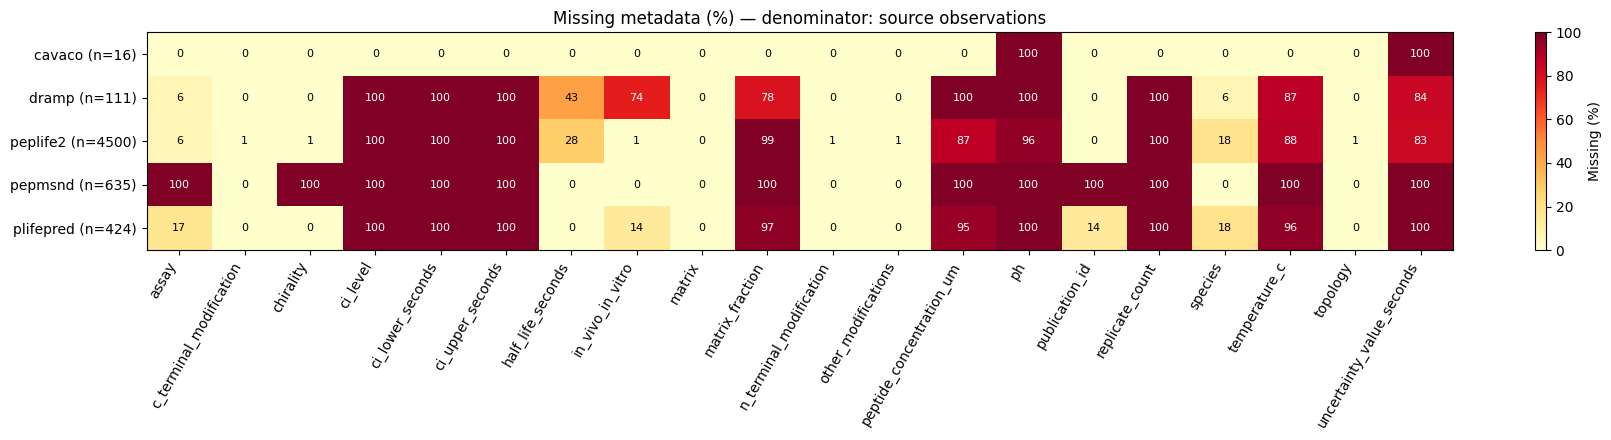

In [2]:
FIGURE_WIDTH = 18
fig = plot_processed_missingness(tables["missingness"], width=FIGURE_WIDTH)
display(fig)
plt.close(fig)

**2. Source sizes and overlap.** Counts distinguish source observations from reported peptide descriptions. The first matrix matches exact sequence strings; the second also requires the same recorded chemistry, with missing fields kept explicit rather than treated as wildcards.

,Source,Source observations,observations_share_percent,Distinct source IDs,source_records_within_source_percent,Peptide descriptions,reported_peptides_union_coverage_percent,Sequence strings,sequence_strings_union_coverage_percent
0,cavaco,16,0.281393,16,100.000000,16,0.515630,16,0.723000
1,dramp,111,1.952163,110,99.099099,108,3.480503,87,3.931315
2,peplife2,4500,79.141752,4500,100.000000,2417,77.892362,1844,83.325802
3,pepmsnd,635,11.167781,635,100.000000,604,19.465034,587,26.525079
4,plifepred,424,7.456912,261,61.556604,261,8.411215,244,11.025757


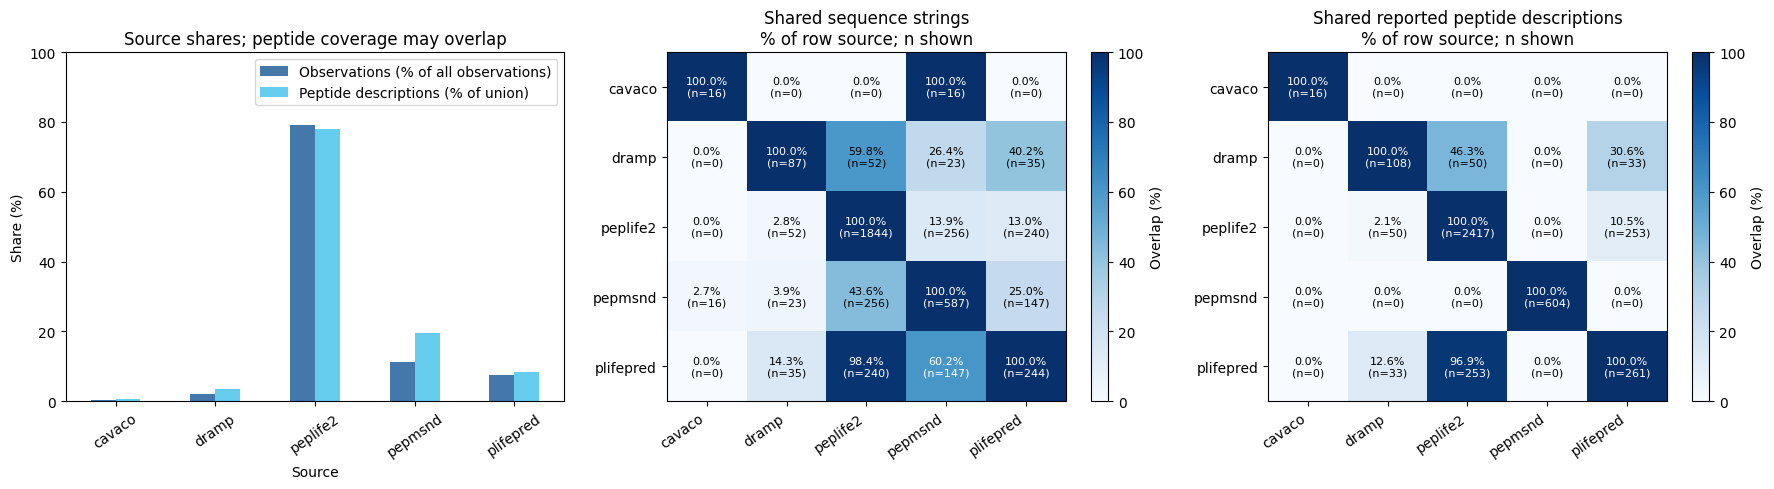

In [3]:
display(tables["source_counts"].rename(columns={
    "source": "Source", "observations": "Source observations", "source_records": "Distinct source IDs",
    "reported_peptides": "Peptide descriptions", "sequence_strings": "Sequence strings",
}).style.set_caption("Source counts: repeated author views remain separate observations"))
fig = plot_processed_sources(tables["source_counts"], tables["sequence_overlap"], tables["peptide_overlap"])
display(fig)
plt.close(fig)

**3. Reported conditions.** Bars count observations by species, biological matrix and assay mode; human and mouse labels are bold. Unreported context is shown explicitly.

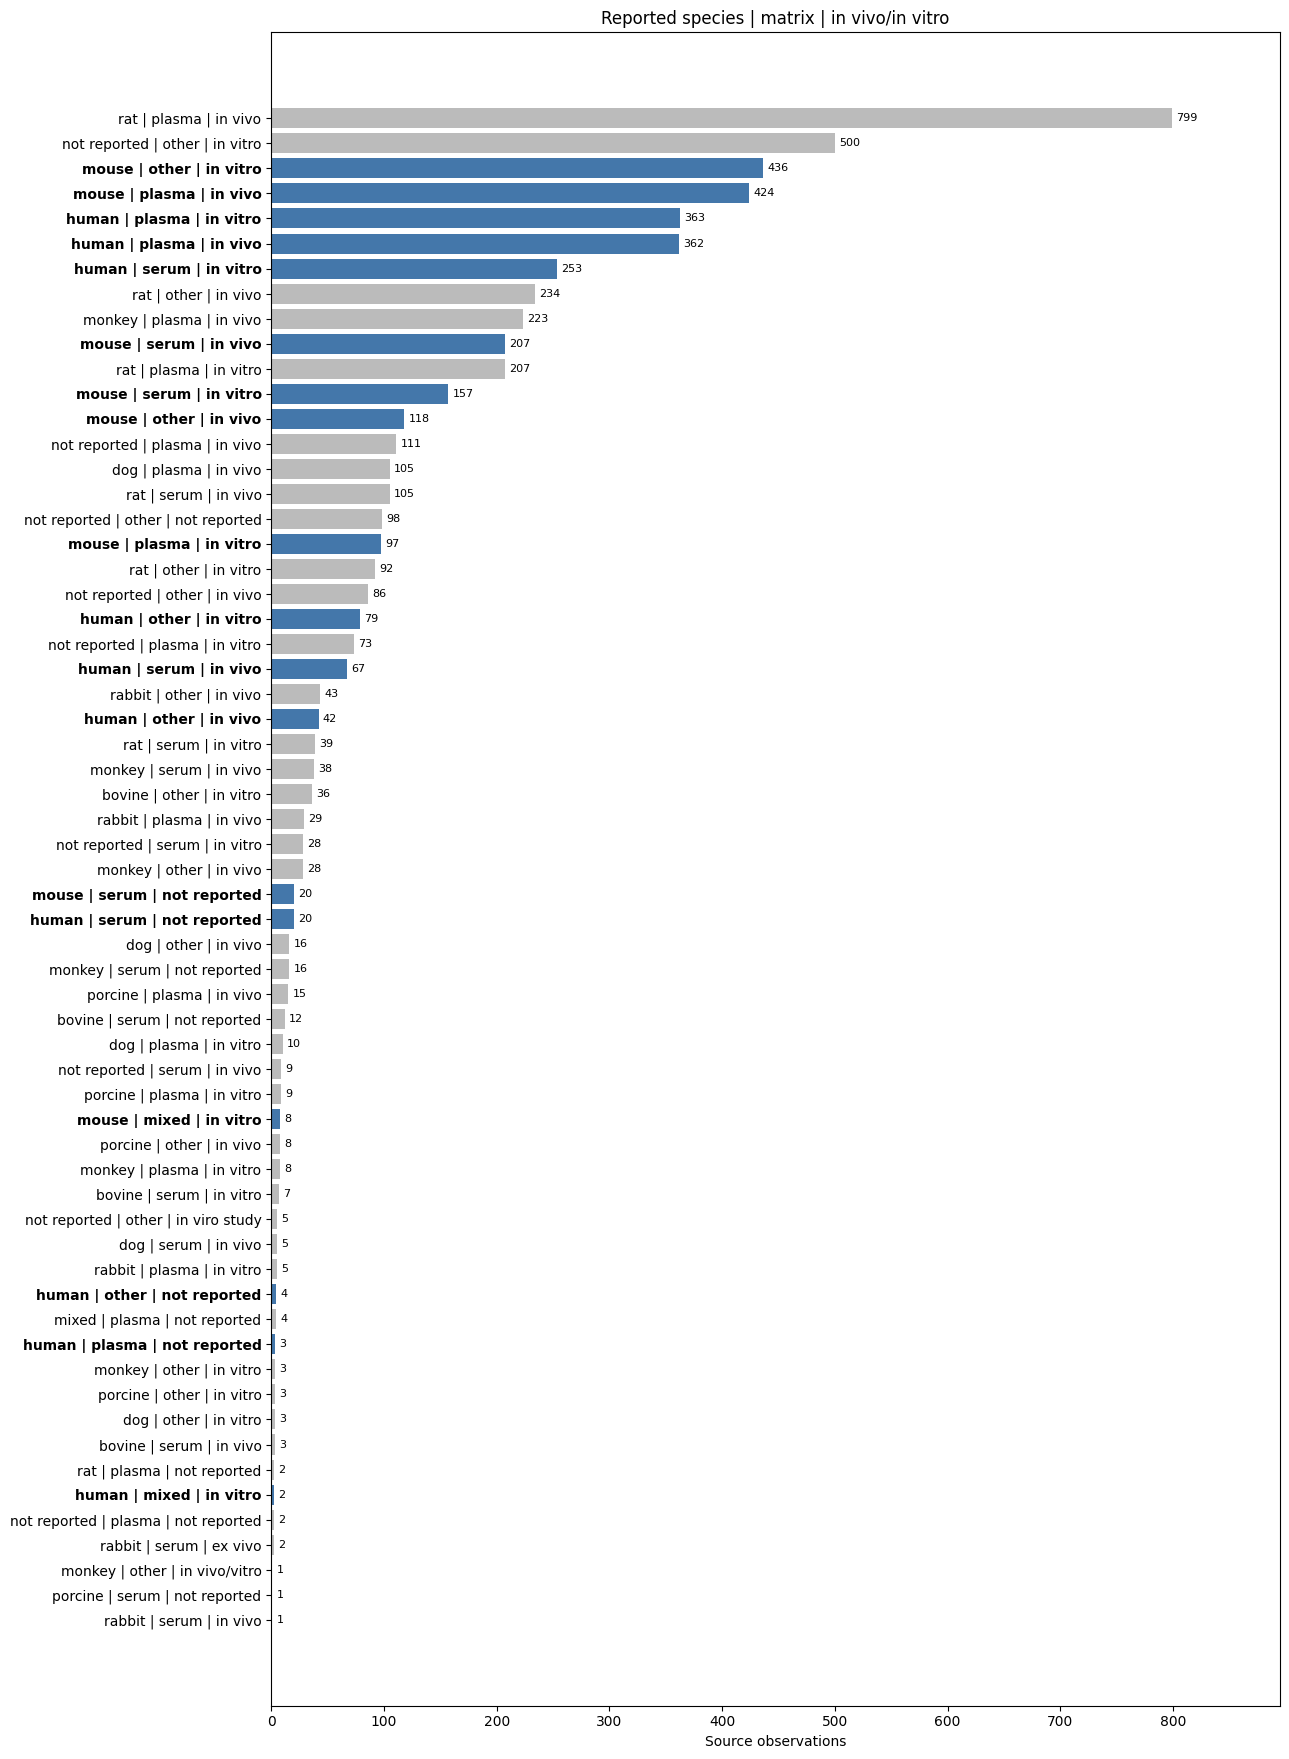

In [4]:
FOCUS_SPECIES = ("human", "mouse")
fig = plot_processed_conditions(tables["conditions"], focus_species=FOCUS_SPECIES)
display(fig)
plt.close(fig)

**4. Shared human/mouse peptide measurements.** Each x group is one reported peptide description with equal reported conditions across at least two sources; colors show individual source values, and vertical segments show reported CI where present. All groups are paginated, and missing numeric conditions are labelled “not reported”: their equality does not establish experimental equivalence.

58 cross-source peptide/context groups; all are plotted.


,Plot group,Sequence,Reported conditions,Sources,Source observations,Minimum (s),Maximum (s),Maximum / minimum
15,C016,SCSlPQT,mouse | serum | in vivo fraction=not reported; T=not reported; pH=not reported; peptide=not reported,2,10,1200.000000,2940.000000,2.45
42,C043,YAEGTFISDYSIAMDKIHQQDFVNWLLAQKGKKNDWKHNITQ,human | plasma | in vitro fraction=not reported; T=not reported; pH=not reported; peptide=2000 µM,2,3,21600.000000,43200.000000,2.00
23,C024,HDEFERHAEGTFTSDVSSYLEGQAAKEFIAWLVKGR,human | plasma | in vivo fraction=not reported; T=not reported; pH=not reported; peptide=not reported,2,3,684.000000,1032.000000,1.51
8,C009,DNPSLSIDLTFHLLRTLLELARTQSQRERAEQNRIIFDSV,human | plasma | in vivo fraction=not reported; T=not reported; pH=not reported; peptide=not reported,2,4,3120.000000,3240.000000,1.04
44,C045,CRRWQWRMKKLGC,human | serum | in vitro fraction=not reported; T=not reported; pH=not reported; peptide=5 µM,2,4,6600.000000,6600.000000,1.00
33,C034,HSDGIFTDSYSRYRKQMAVKKYLAAVLGKRYKQRVKNK,human | plasma | in vitro fraction=not reported; T=not reported; pH=not reported; peptide=not reported,2,2,258.000000,258.000000,1.00
34,C035,HADGVFTSDFSKLLGQLSAKKYLESLM,human | plasma | in vivo fraction=not reported; T=not reported; pH=not reported; peptide=not reported,2,2,390.000000,390.000000,1.00
35,C036,GWTLNSAGYLLGPHAVGNHRSFSDKNGLTS,human | serum | in vivo fraction=not reported; T=not reported; pH=not reported; peptide=not reported,2,3,222.000000,222.000000,1.00
36,C037,VDKPPYLPRPRPPRRIYNR,mouse | serum | in vivo fraction=0.25; T=not reported; pH=not reported; peptide=not reported,2,2,4080.000000,4080.000000,1.00
37,C038,VDKPPYLPRPRPPRRIYNR,mouse | serum | in vivo fraction=1; T=not reported; pH=not reported; peptide=not reported,3,3,1500.000000,1500.000000,1.00


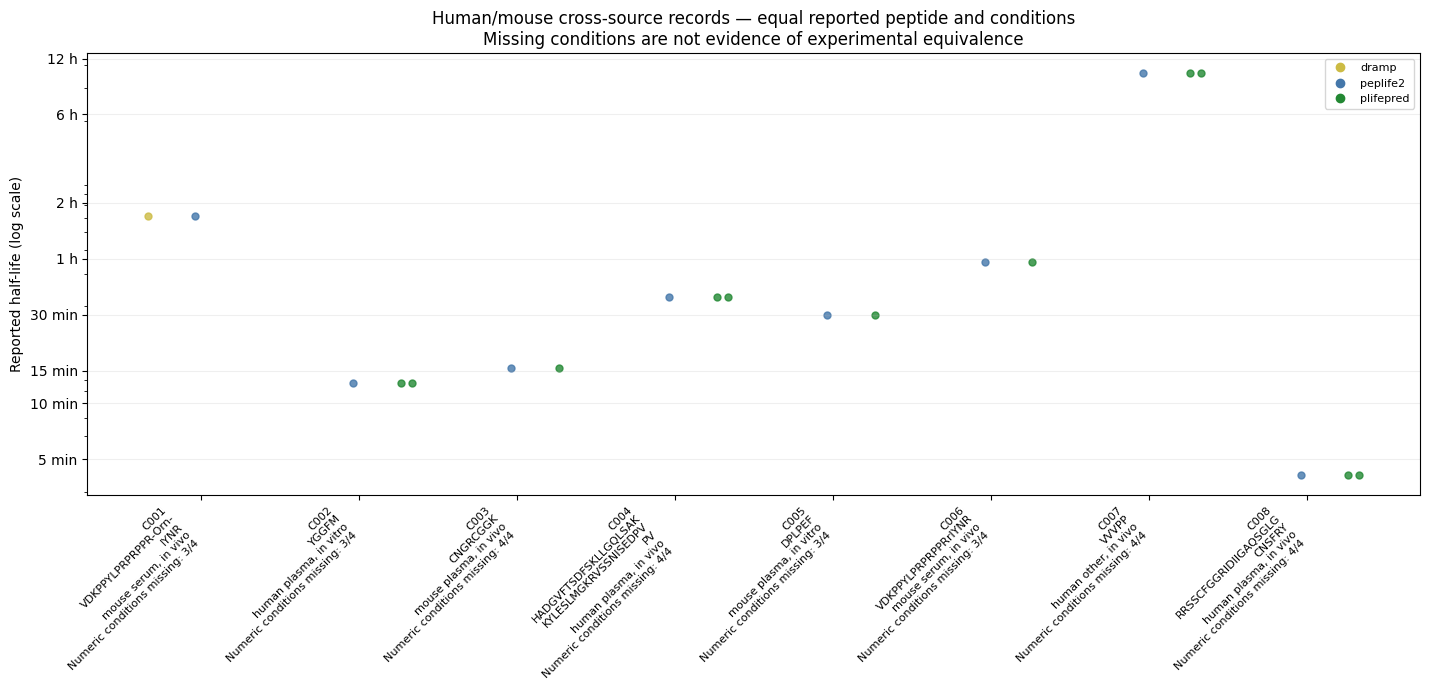

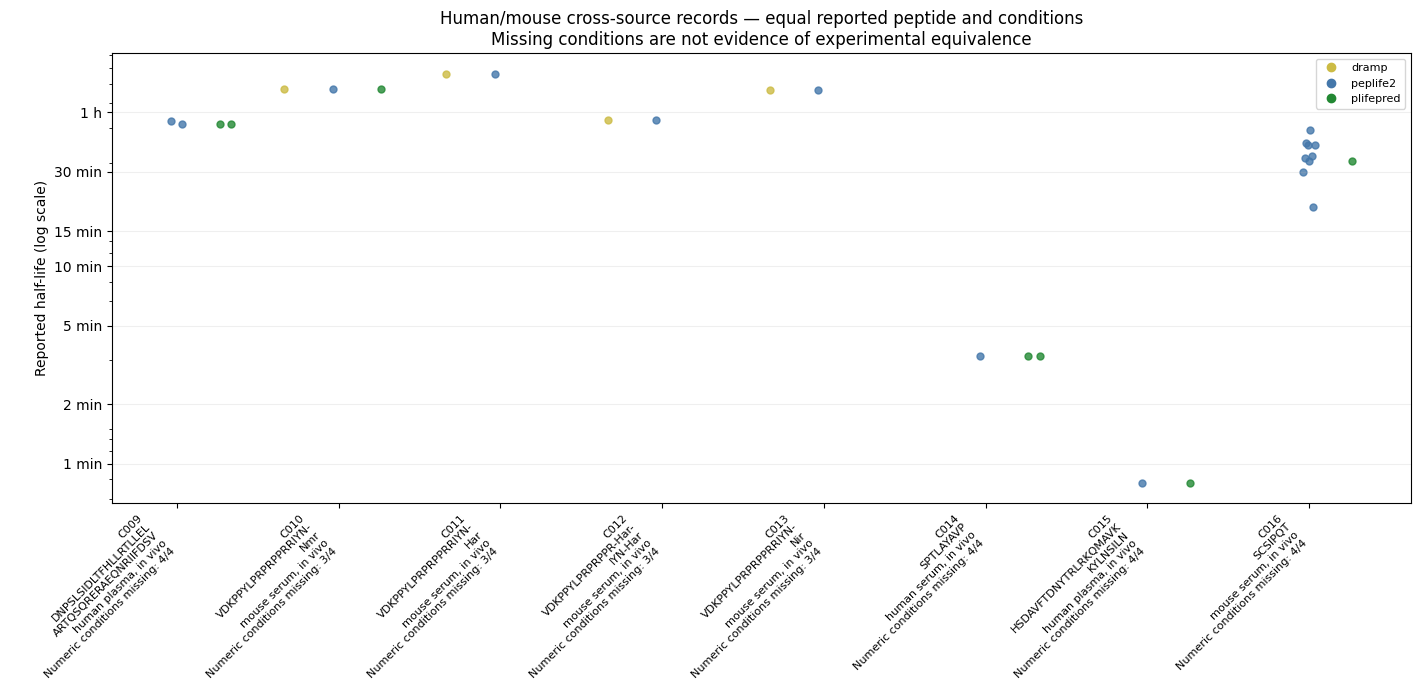

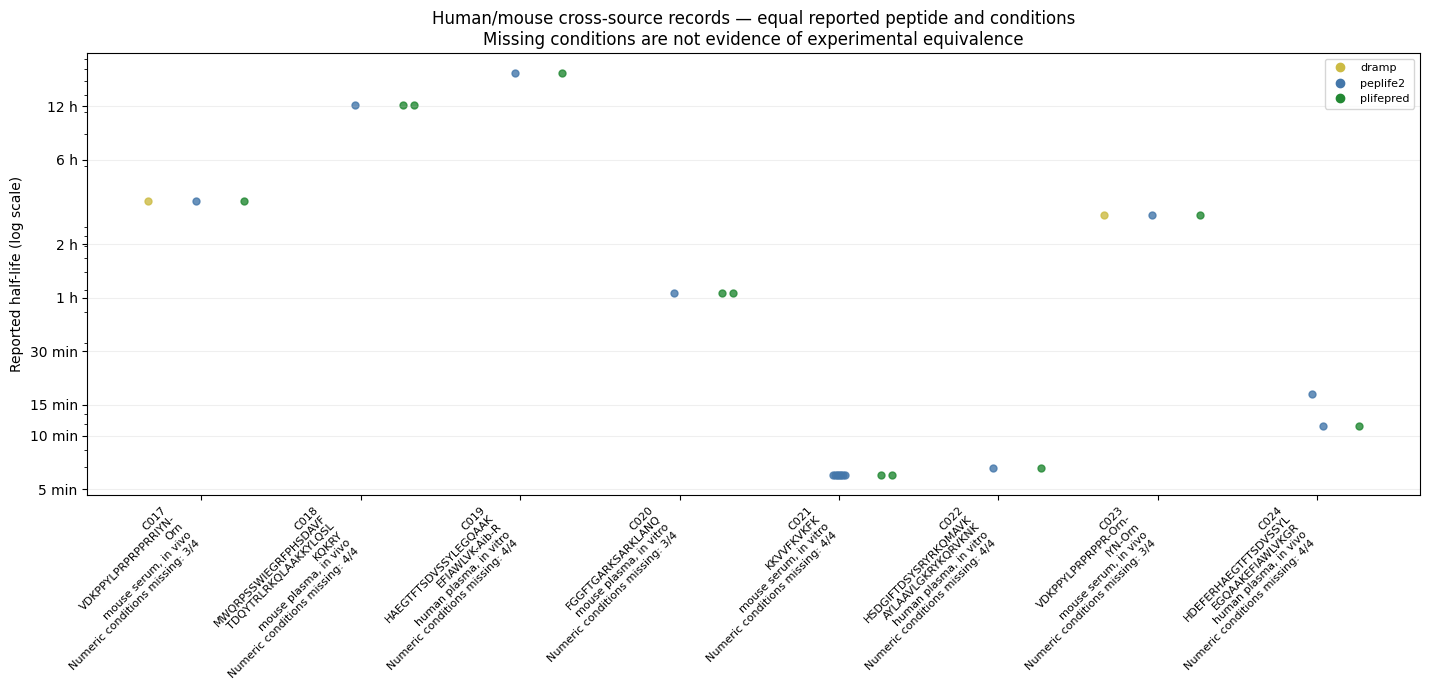

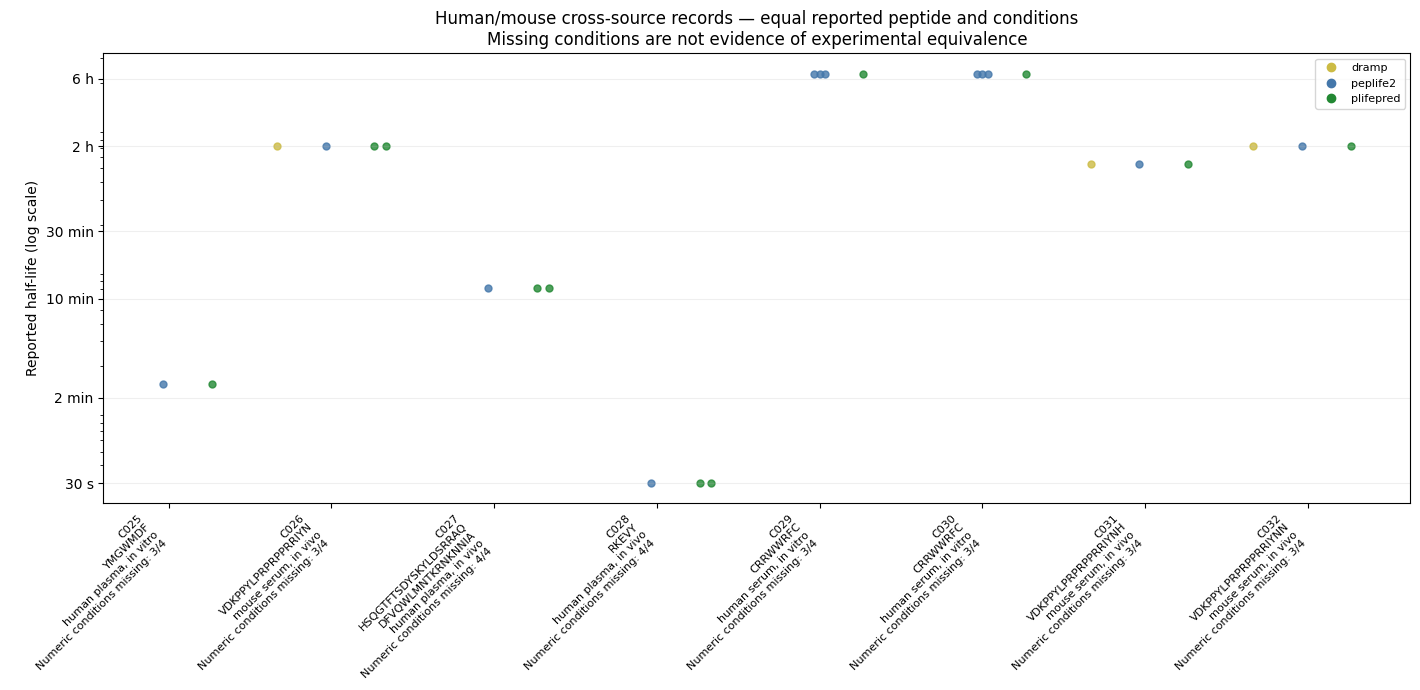

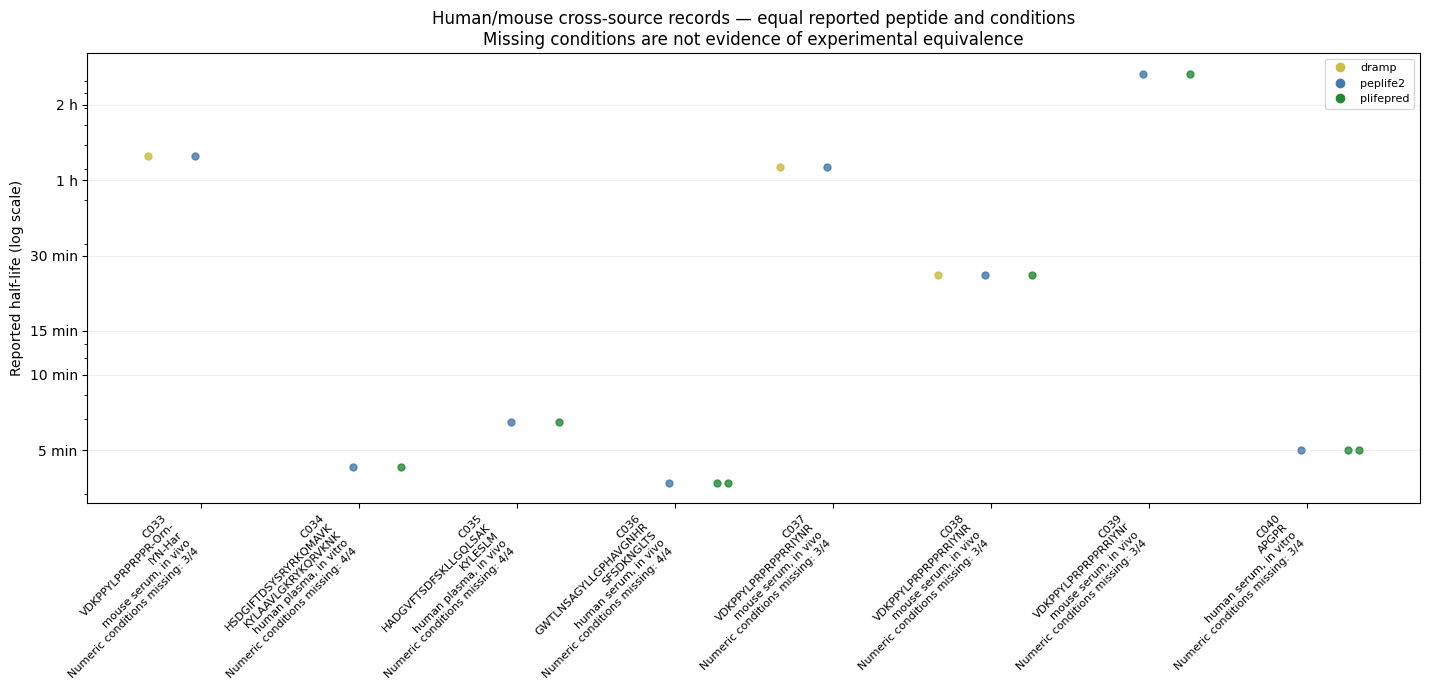

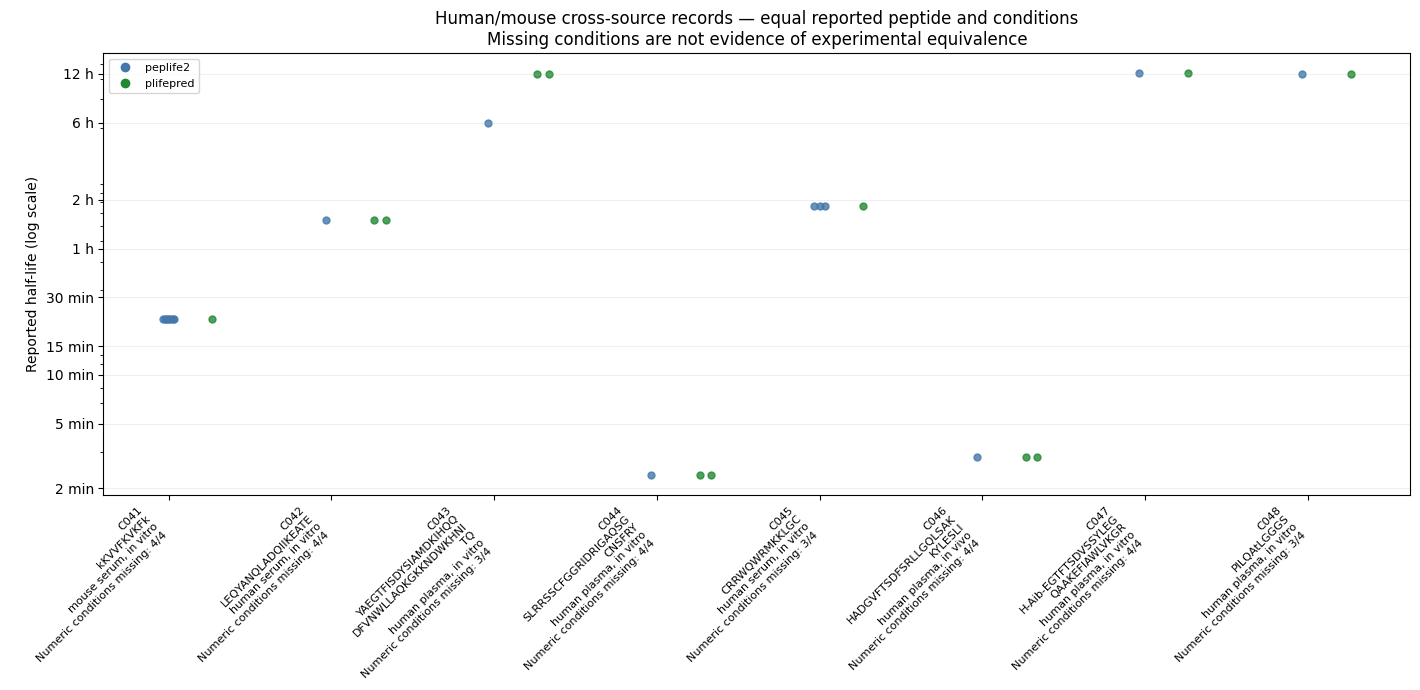

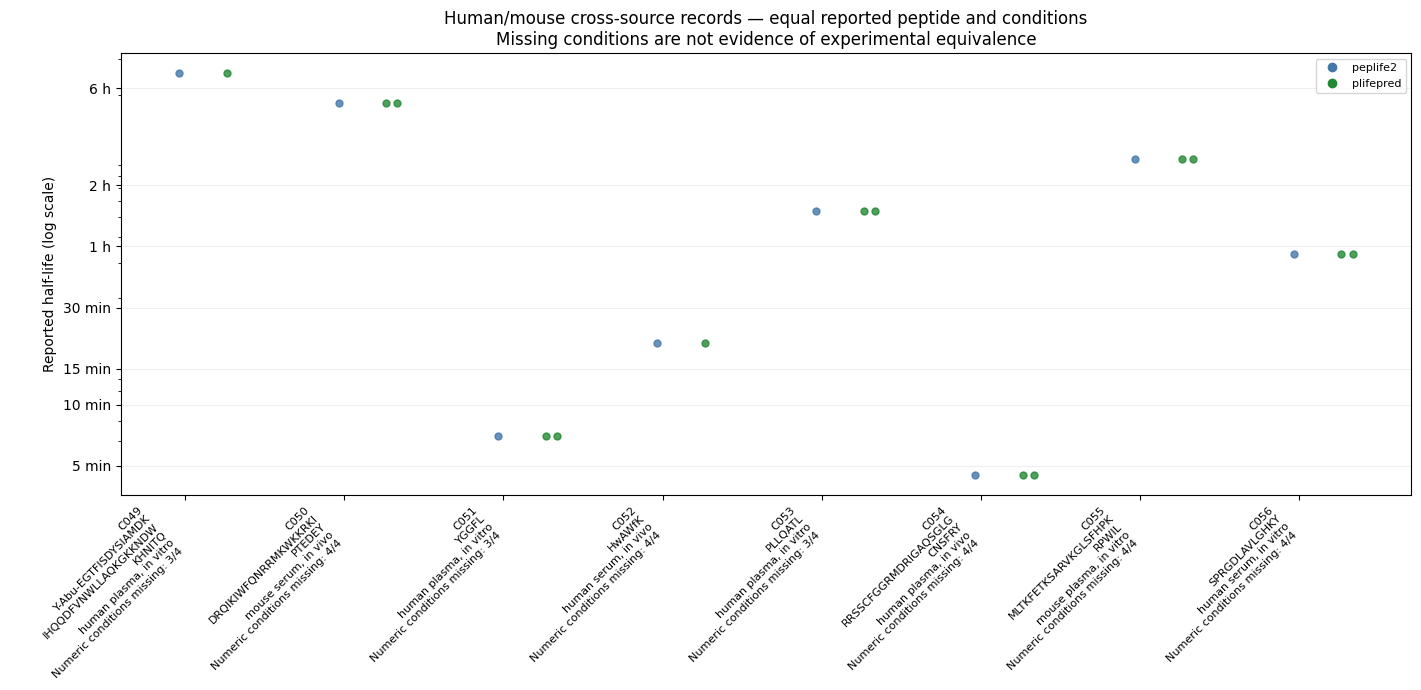

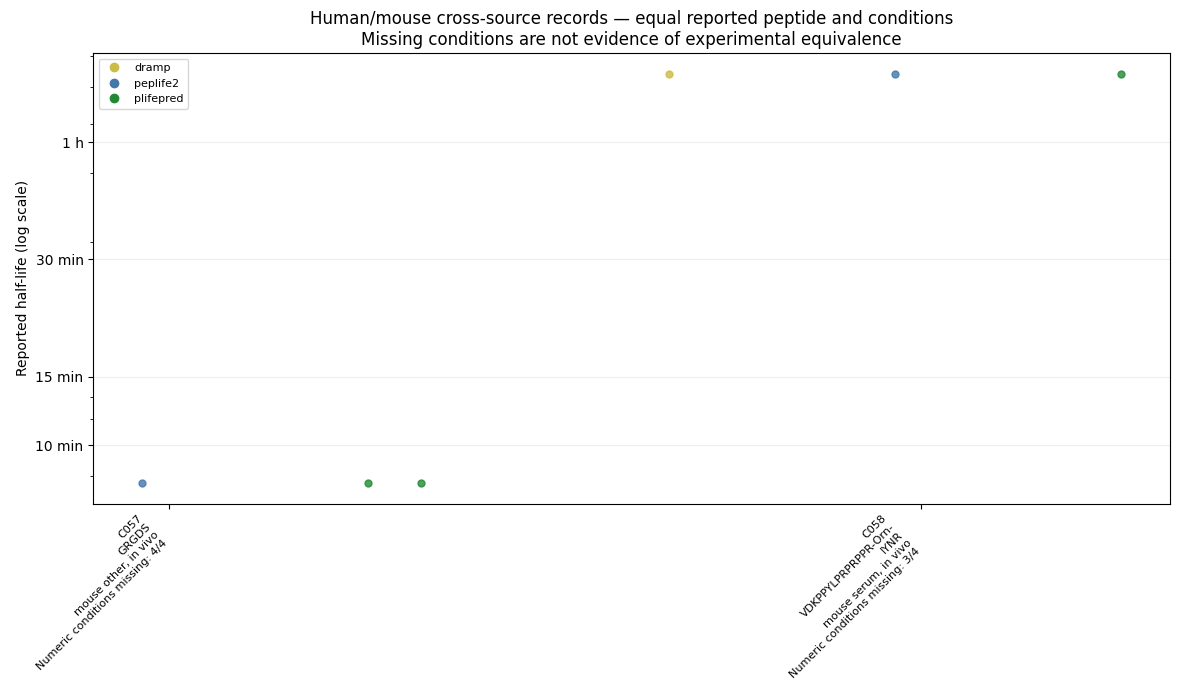

In [5]:
GROUPS_PER_FIGURE = 8
TIME_SCALE = "log"  # "log" or "linear"
print(f"{len(tables['shared_comparisons'])} cross-source peptide/context groups; all are plotted.")
display(tables["shared_comparisons"].sort_values("max_to_min_ratio", ascending=False).head(15).rename(columns={
    "comparison_id": "Plot group", "sequence": "Sequence", "context_label": "Reported conditions",
    "sources": "Sources", "observations": "Source observations", "min_seconds": "Minimum (s)",
    "max_seconds": "Maximum (s)", "max_to_min_ratio": "Maximum / minimum",
}).style.format({"Maximum / minimum": "{:.2f}"}).set_caption("Largest observed spreads (first 15 groups); full table available in memory"))
for fig in plot_processed_agreement(tables["shared_measurements"], groups_per_figure=GROUPS_PER_FIGURE, scale=TIME_SCALE):
    display(fig)
    plt.close(fig)

**5. Half-life distributions by source and condition.** Exact positive half-lives are shown for each source and then pooled, grouped by reported species, matrix and assay mode; numeric assay conditions can still vary within each row. Background bands and point colors mark short (<30 min), medium (30 min–6 h inclusive) and long (>6 h); grey densities and all individual points show variation, while bounds, approximations and unresolved labels are excluded.

Plotting 2,071 observations across 16 human/mouse conditions.


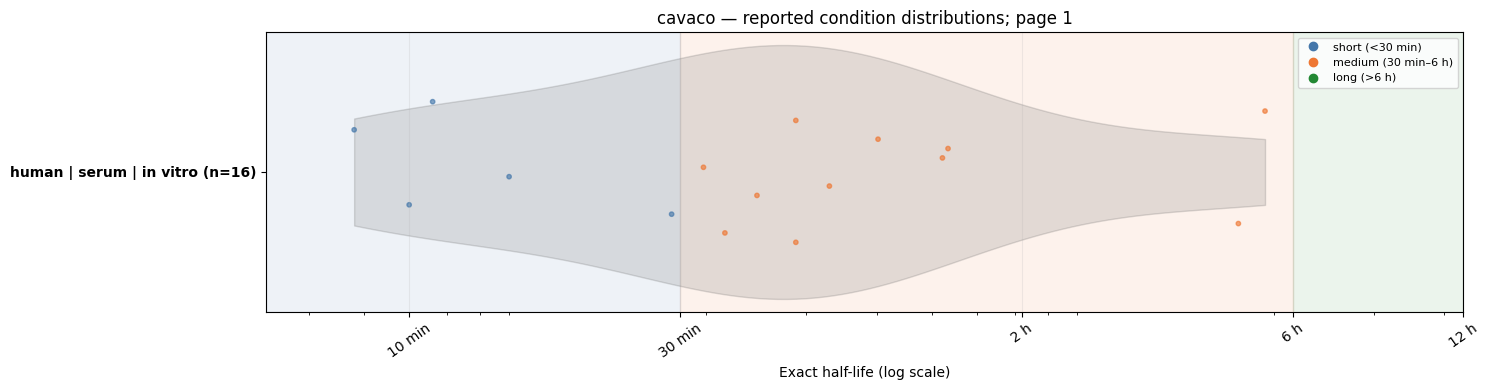

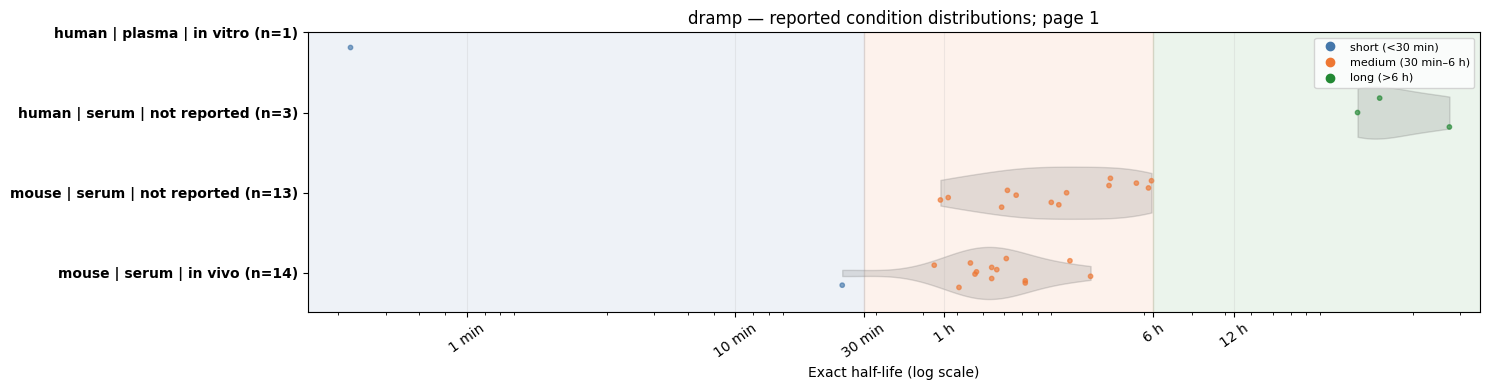

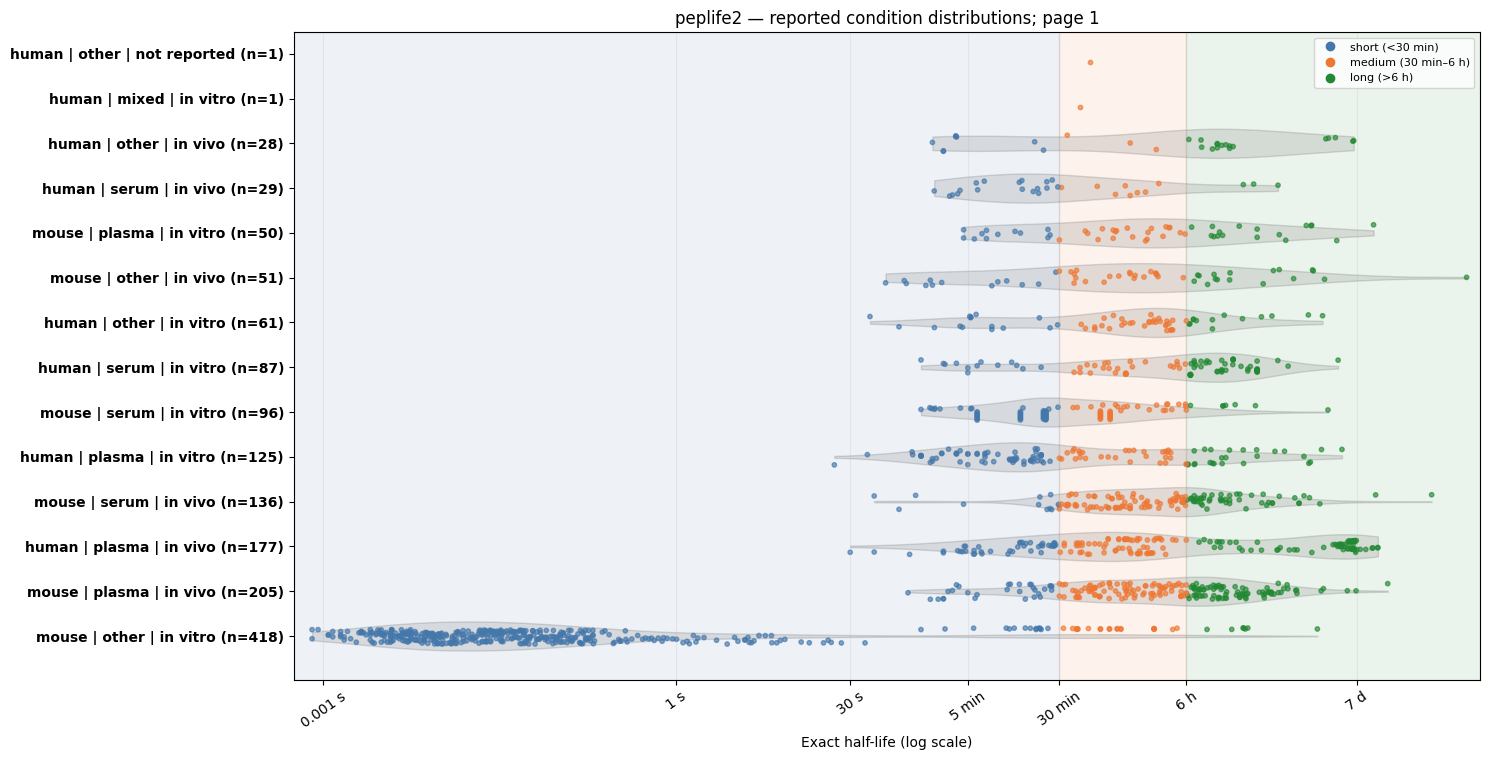

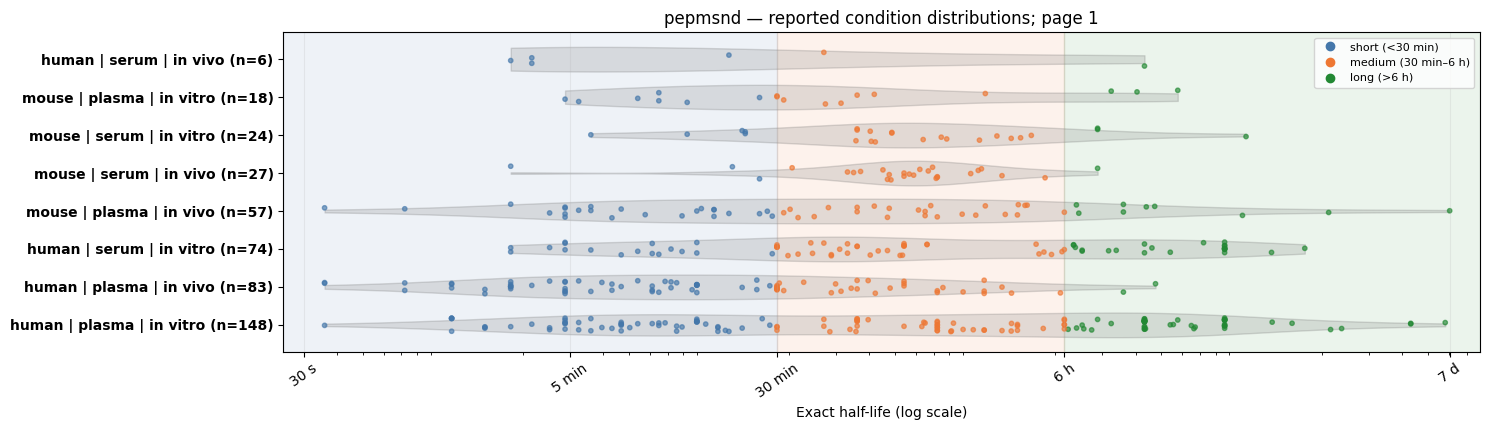

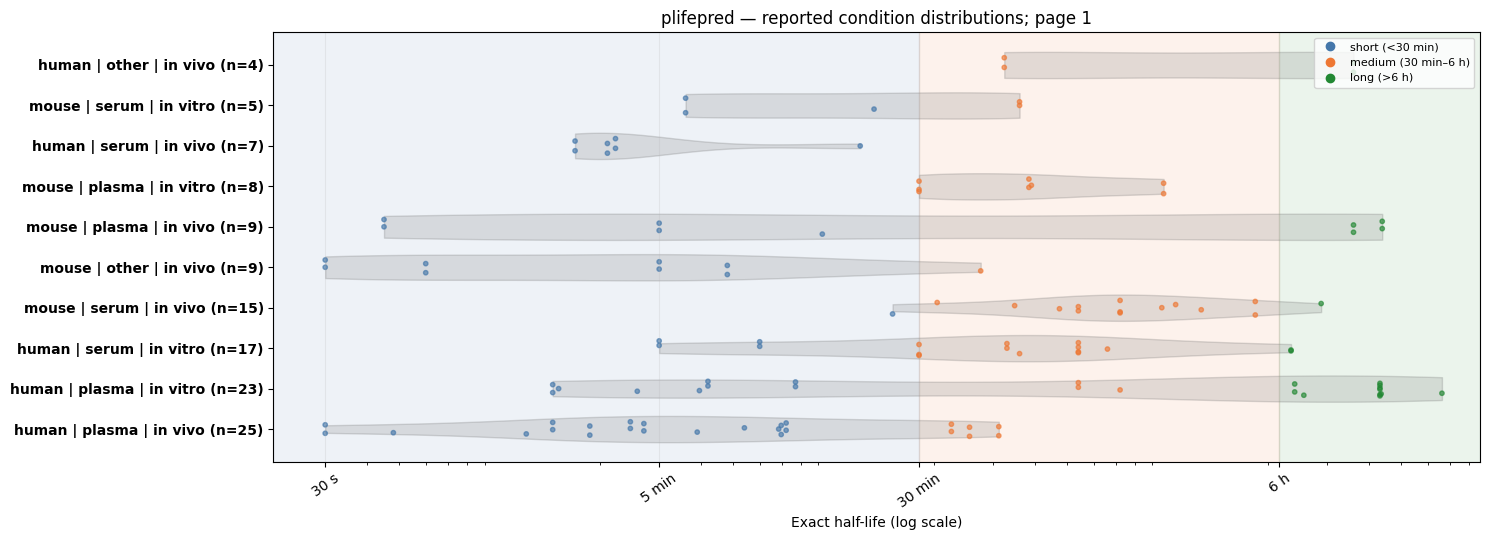

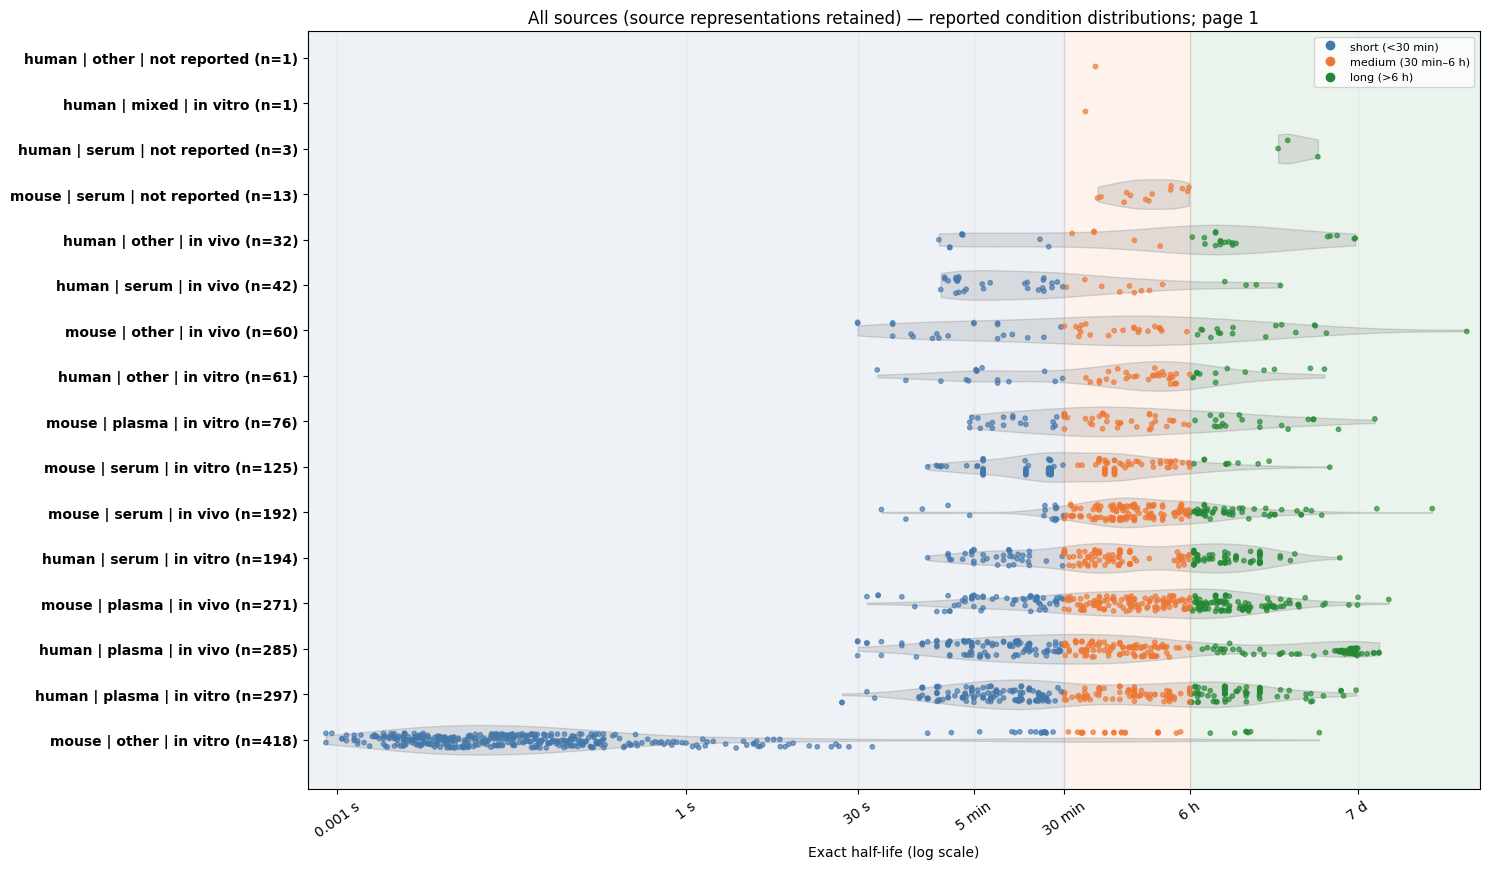

In [7]:
CONDITIONS_PER_FIGURE = 16
TIME_SCALE = "log"  # "log" or "linear"
FOCUS_SPECIES = ("human", "mouse")

# Exclude records without a reported human or mouse species before choosing sources or plotting.
duration_values = tables["duration_values"]
duration_values = duration_values.loc[duration_values.species.isin(FOCUS_SPECIES)]
print(f"Plotting {len(duration_values):,} observations across {duration_values.condition_label.nunique():,} human/mouse conditions.")

for source in [*sorted(duration_values.source.unique()), None]:
    for fig in plot_processed_durations(
        duration_values,
        source=source,
        conditions_per_figure=CONDITIONS_PER_FIGURE,
        scale=TIME_SCALE,
        focus_species=FOCUS_SPECIES,
    ):
        display(fig)
        plt.close(fig)


**Observed:** The dataset contains 5,686 source observations and 3,103 reported peptide descriptions; 4,261 observations have exact positive half-lives. There are 58 shared human/mouse peptide/context groups (179 source representations); all are plotted, and missing assay metadata remains explicit.

## Common numerical parameters

`common_parameters` contains the same named numeric feature columns as the other sources. Half-lives are in seconds; apparent exponential rates are ln(2)/half_life. Original bounds, chemistry and source identities remain available. All transformations stay in memory; no CSV or database is written.

In [8]:
# Use the independent data library from this checkout.
import sys
sys.path.insert(0, str(ROOT / "assets/tools/proteolysis_data_manager/src"))
from proteolysis_data_manager.integration.merge import (
    build_dataset, parse_dataset, add_merops_scores,
)
contract = build_dataset(
    ROOT / "data/proteolysis",
    sources=["peplife2", "pepmsnd", "dramp", "plifepred", "cavaco"],
)
common_parameters = contract.to_frame()
display(common_parameters.loc[common_parameters.half_life.notna()].groupby("source_db", sort=False).head(1)[[
    "source_db", "substrate_sequence", "half_life", "apparent_rate_s_inv", "apparent_rate_basis",
]])


,source_db,substrate_sequence,half_life,apparent_rate_s_inv,apparent_rate_basis
12,peplife2,RRWQWR,3600.0,0.000193,exponential_half_life
4500,pepmsnd,AGCKNFFWKTFTSC,144.0,0.004814,exponential_half_life
5136,dramp,RRWQWR,3600.0,0.000193,exponential_half_life
5246,plifepred,RRWQWR,1800.0,0.000385,exponential_half_life
5670,cavaco,GAAQAAGSGAAQAAG,2880.0,0.000241,exponential_half_life
